# Problem: Adversarial Attacks

## **<span style="color:orange">Importing Libraries, Declaring Constants, Setting Seed & DEVICE </span>**

In [18]:
import sys
sys.path.append("pytorch-cifar-models")

import pytorch_cifar_models as pcm

Library

In [19]:
import os
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm import tqdm
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

Set DEVICE

In [20]:
DEVICE = "cpu"
# if torch.backends.mps.is_available():
#     DEVICE = "mps"
# elif torch.cuda.is_available():
#     DEVICE = "cuda"

print(f"Using device: {DEVICE}")

Using device: cpu


Constants

In [21]:
BATCH_SIZE = 4

In [22]:
CIFAR10_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [23]:
CIFAR10_DIR = "./cifar10_correct_samples"
RESENET20_WEIGHTS = "./cifar10_resnet20-4118986f.pt"

## **<span style="color:orange">Load Model & Data</span>**

Load model

In [24]:
model = pcm.cifar10_resnet20(pretrained=False)

In [25]:
state_dict = torch.load(RESENET20_WEIGHTS, map_location=DEVICE)
model.load_state_dict(state_dict)
model.to(DEVICE)
model.eval()

C:\Users\Amin\AppData\Local\Temp\ipykernel_18820\3019721327.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(RESENET20_WEIGHTS, map_location=DEVIC

CifarResNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias

Load image

In [26]:
class CIFARCustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform

        self.files = [
            f for f in os.listdir(root_dir)
            if f.endswith(".png")
        ]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]
        path = os.path.join(self.root_dir, filename)

        # load image
        image = Image.open(path).convert("RGB")

        # parse label from filename: "..._true3.png"
        label_str = filename.split("_true")[1].split(".png")[0]
        label = int(label_str)

        if self.transform:
            image = self.transform(image)

        return image, label

In [27]:
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.flatten().tolist(),
                        std=std.flatten().tolist())
])

dataset = CIFARCustomDataset(
    root_dir=CIFAR10_DIR,
    transform=transform
)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

In [28]:
print(f"Number of images: {len(dataset)}")
print(f"Number of batches: {len(dataloader)}")

Number of images: 25
Number of batches: 7


Check Model and Dataset Load

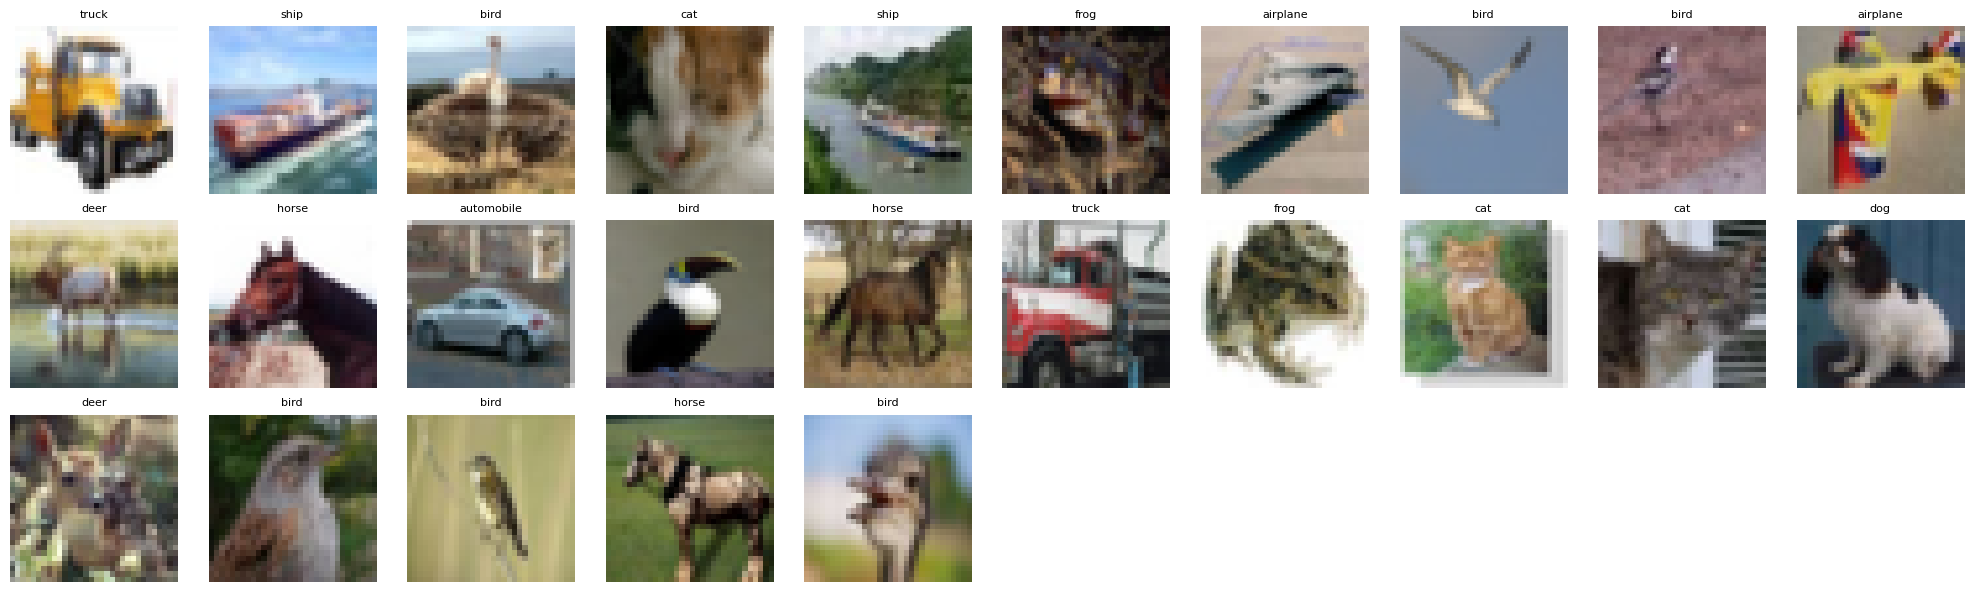

In [29]:
num_images = len(dataset)
cols = 10
rows = 3

fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2 * rows))
axes = np.array(axes).reshape(-1)

for i in range(num_images):
    img, true_lbl = dataset[i]
    img = img * std + mean
    img = torch.clamp(img, 0, 1)

    axes[i].imshow(img.permute(1, 2, 0).numpy())
    axes[i].set_title(f"{CIFAR10_CLASSES[true_lbl]}", fontsize=8)
    axes[i].axis("off")

for j in range(num_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [36]:
def evaluate(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(data_loader):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = correct / total
    return accuracy

In [39]:
accuracy_clean_data = evaluate(model, dataloader)
print(f"Accuracy of the model on the {len(dataset)} clean images: {accuracy_clean_data*100:.2f}%")

100%|██████████| 7/7 [00:00<00:00, 97.60it/s]

Accuracy of the model on the 25 clean images: 100.00%


## **<span style="color:orange">Attacks</span>**

## **<span style="color:orange">FGSM</span>**

In [40]:
from torch.utils.data import TensorDataset
import torch.nn as nn

In [44]:
EPSILON = 0.03

In [41]:
def normalize(img):
    mean_device = mean.to(img.device)
    std_device = std.to(img.device)

    if img.dim() == 4:
        mean_device = mean_device.unsqueeze(0)
        std_device = std_device.unsqueeze(0)

    return (img - mean_device) / std_device

def denormalize(img):
    mean_device = mean.to(img.device)
    std_device = std.to(img.device)

    if img.dim() == 4:
        mean_device = mean_device.unsqueeze(0)
        std_device = std_device.unsqueeze(0)

    return img * std_device + mean_device

def fix_image(img):
    img_pixel = denormalize(img)
    img_pixel = torch.clamp(img_pixel, 0, 1)
    img_normalized = normalize(img_pixel)

    return img_normalized

In [ ]:
def do_fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().to(DEVICE)
    labels = labels.clone().detach().to(DEVICE)
    images.requires_grad = True
    outputs = model(images)
    loss_func = nn.CrossEntropyLoss()
    loss = loss_func(outputs, labels)
    model.zero_grad()
    loss.backward()
    gradient = images.grad.data
    adversarial_images = images + epsilon * gradient.sign()
    adversarial_images = fix_image(adversarial_images)

    return adversarial_images.detach()

In [ ]:
def create_fgsm_dataset(model, data_loader, epsilon):
    model.eval()
    clean_images_list = []
    adversarial_images_list = []
    labels_list = []

    for images, labels in tqdm(data_loader):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        adversarial_images = do_fgsm_attack(model, images, labels, epsilon)
        clean_images_list.append(images.detach().cpu())
        adversarial_images_list.append(adversarial_images.detach().cpu())
        labels_list.append(labels.detach().cpu())

    clean_images = torch.cat(clean_images_list, dim=0)
    adversarial_images = torch.cat(adversarial_images_list, dim=0)
    labels = torch.cat(labels_list, dim=0)
    adversarial_dataset = TensorDataset(adversarial_images, labels)
    loader = DataLoader(adversarial_dataset, batch_size=BATCH_SIZE, shuffle=False)

    return clean_images, adversarial_images, labels, loader

In [ ]:
clean_images_fgsm, adversarial_images_fgsm, labels_fgsm, fgsm_loader = create_fgsm_dataset(model=model, data_loader=dataloader, epsilon=EPSILON)
accuracy_fgsm = evaluate(model, fgsm_loader)
print(f"\nFGSM Accuracy : {accuracy_fgsm * 100:.2f}%")

100%|██████████| 7/7 [00:00<00:00, 103.56it/s]


FGSM Accuracy : 28.00%


In [50]:
def get_predictions(model, images):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(images), BATCH_SIZE):
            batch = images[i:i+BATCH_SIZE].to(DEVICE)
            outputs = model(batch)
            _, predicted = torch.max(outputs, dim=1)
            preds.append(predicted.cpu())

    return torch.cat(preds, dim=0)

In [ ]:
clean_preds_fgsm = get_predictions(model, clean_images_fgsm)
adversarial_fgsm = get_predictions(model, adversarial_images_fgsm)
wrong_indices_fgsm = torch.where(adversarial_fgsm != labels_fgsm)[0]
print(f"Number of wrong predictions after FGSM : {len(wrong_indices_fgsm)}")

Number of wrong predictions after FGSM : 18


C:\Users\Amin\AppData\Local\Temp\ipykernel_18820\1683154430.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


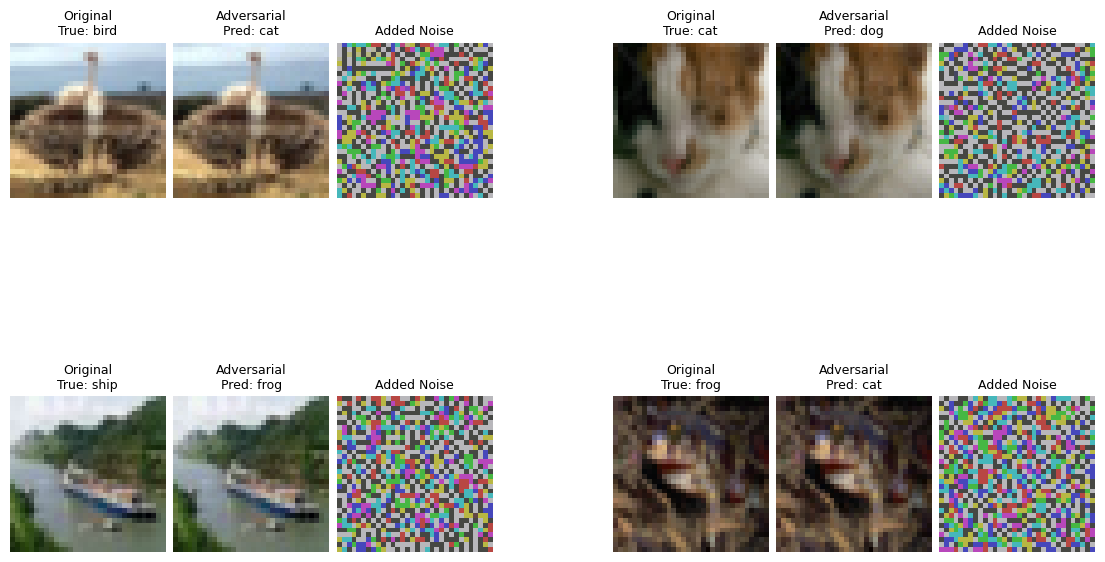

In [ ]:
def show_fgsm_examples(clean_images, adversarial_images, labels, adversarial_preds, wrong_indices, num_examples):
    num_examples = min(num_examples, len(wrong_indices), 4)
    fig = plt.figure(figsize=(14, 8))
    outer_grid = fig.add_gridspec(2, 2, wspace=0.25, hspace=0.35)

    for example_num in range(num_examples):
        idx = wrong_indices[example_num].item()
        clean_img = clean_images[idx]
        adversarial_img = adversarial_images[idx]

        clean_img_show = denormalize(clean_img).cpu()
        adversarial_img_show = denormalize(adversarial_img).cpu()

        clean_img_show = torch.clamp(clean_img_show, 0, 1)
        adversarial_img_show = torch.clamp(adversarial_img_show, 0, 1)
        noise = adversarial_img_show - clean_img_show

        noise_show = noise * 30 + 0.5
        noise_show = torch.clamp(noise_show, 0, 1)

        true_label = labels[idx].item()
        predicted_label = adversarial_preds[idx].item()

        row = example_num // 2
        col = example_num % 2

        inner_grid = outer_grid[row, col].subgridspec(1, 3, wspace=0.05)

        ax1 = fig.add_subplot(inner_grid[0, 0])
        ax2 = fig.add_subplot(inner_grid[0, 1])
        ax3 = fig.add_subplot(inner_grid[0, 2])

        ax1.imshow(clean_img_show.permute(1, 2, 0).numpy())
        ax1.set_title(f"Original\nTrue: {CIFAR10_CLASSES[true_label]}", fontsize=9)
        ax1.axis("off")

        ax2.imshow(adversarial_img_show.permute(1, 2, 0).numpy())
        ax2.set_title(f"Adversarial\nPred: {CIFAR10_CLASSES[predicted_label]}", fontsize=9)
        ax2.axis("off")

        ax3.imshow(noise_show.permute(1, 2, 0).numpy())
        ax3.set_title("Added Noise", fontsize=9)
        ax3.axis("off")

    plt.tight_layout()
    plt.show()

show_fgsm_examples(clean_images=clean_images_fgsm, adversarial_images=adversarial_images_fgsm, labels=labels_fgsm, adversarial_preds=adversarial_fgsm, wrong_indices=wrong_indices_fgsm, num_examples=4)

## **<span style="color:orange">PGD</span>**

In [64]:
EPSILON_PGD = 0.03
ALPHA_PGD = 0.005
NUM_STEPS_PGD = 20

In [ ]:
def do_pgd_attack(model, images, labels, epsilon, alpha, num_steps):
    model.eval()
    images = images.clone().detach().to(DEVICE)
    labels = labels.clone().detach().to(DEVICE)
    adversarial_images = images.clone().detach()
    loss_func = nn.CrossEntropyLoss()

    for _ in range(num_steps):
        adversarial_images.requires_grad = True
        outputs = model(adversarial_images)
        loss = loss_func(outputs, labels)
        model.zero_grad()
        loss.backward()
        gradient = adversarial_images.grad.data
        adversarial_images = adversarial_images + alpha * gradient.sign()
        perturbation = torch.clamp(adversarial_images - images, min=-epsilon, max=epsilon)
        adversarial_images = images + perturbation
        adversarial_images = fix_image(adversarial_images)
        adversarial_images = adversarial_images.detach()

    return adversarial_images

In [ ]:
def create_pgd_dataset(model, data_loader, epsilon, alpha, num_steps):
    model.eval()
    clean_images_list = []
    adversarial_images_list = []
    labels_list = []

    for images, labels in tqdm(data_loader):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        adversarial_images = do_pgd_attack(model=model, images=images, labels=labels, epsilon=epsilon, alpha=alpha, num_steps=num_steps)
        clean_images_list.append(images.detach().cpu())
        adversarial_images_list.append(adversarial_images.detach().cpu())
        labels_list.append(labels.detach().cpu())

    clean_images = torch.cat(clean_images_list, dim=0)
    adversarial_images = torch.cat(adversarial_images_list, dim=0)
    labels = torch.cat(labels_list, dim=0)
    adversarial_dataset = TensorDataset(adversarial_images, labels)
    adversarial_loader = DataLoader(adversarial_dataset, batch_size=BATCH_SIZE, shuffle=False)

    return clean_images, adversarial_images, labels, adversarial_loader

In [ ]:
clean_images_pgd, adversarial_images_pgd, labels_pgd, pgd_loader = create_pgd_dataset(model=model, data_loader=dataloader, epsilon=EPSILON_PGD, alpha=ALPHA_PGD, num_steps=NUM_STEPS_PGD)
accuracy_pgd = evaluate(model, pgd_loader)
print(f"PGD accuracy : {accuracy_pgd*100:.2f}%")

100%|██████████| 7/7 [00:00<00:00, 116.48it/s]

PGD accuracy : 4.00%


In [ ]:
clean_preds_pgd = get_predictions(model, clean_images_pgd)
adversarial_preds_pgd = get_predictions(model, adversarial_images_pgd)
wrong_indices_pgd = torch.where(adversarial_preds_pgd != labels_pgd)[0]
print(f"Number of wrong predictions after PGD: {len(wrong_indices_pgd)}")

Number of wrong predictions after PGD: 24


C:\Users\Amin\AppData\Local\Temp\ipykernel_18820\2763264970.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


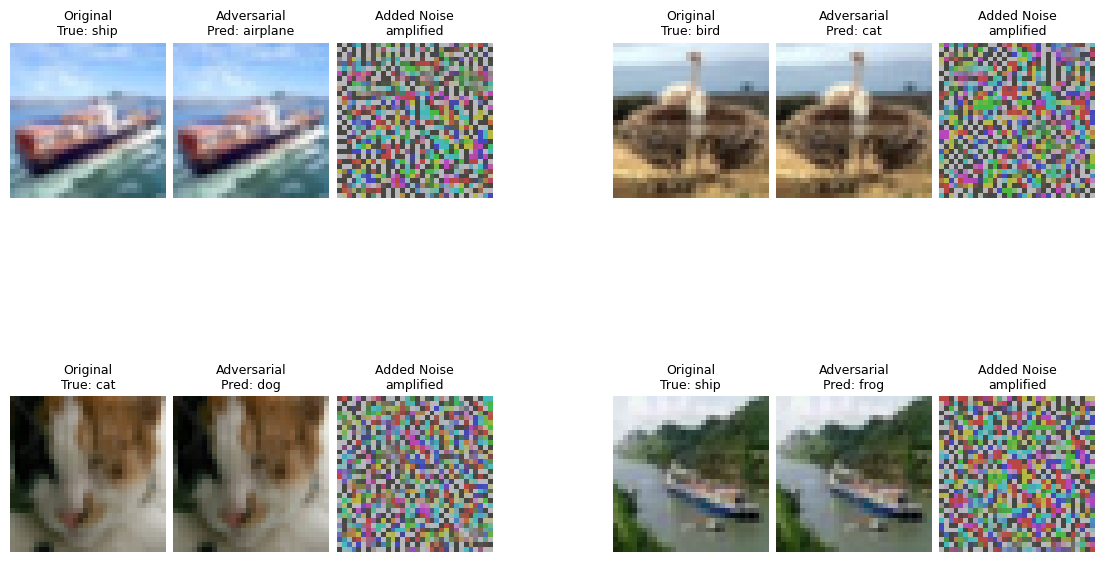

In [ ]:
def show_pgd_examples(clean_images, adversarial_images, labels, adversarial_preds, wrong_indices, num_examples):
    num_examples = min(num_examples, len(wrong_indices), 4)
    fig = plt.figure(figsize=(14, 8))
    outer_grid = fig.add_gridspec(2, 2, wspace=0.25, hspace=0.35)
    for example_num in range(num_examples):
        idx = wrong_indices[example_num].item()

        clean_img = clean_images[idx]
        adversarial_img = adversarial_images[idx]

        clean_img_show = denormalize(clean_img).cpu()
        adversarial_img_show = denormalize(adversarial_img).cpu()

        clean_img_show = torch.clamp(clean_img_show, 0, 1)
        adversarial_img_show = torch.clamp(adversarial_img_show, 0, 1)

        noise = adversarial_img_show - clean_img_show

        noise_show = noise * 30 + 0.5
        noise_show = torch.clamp(noise_show, 0, 1)

        true_label = labels[idx].item()
        predicted_label = adversarial_preds[idx].item()

        row = example_num // 2
        col = example_num % 2

        inner_grid = outer_grid[row, col].subgridspec(1, 3, wspace=0.05)

        ax1 = fig.add_subplot(inner_grid[0, 0])
        ax2 = fig.add_subplot(inner_grid[0, 1])
        ax3 = fig.add_subplot(inner_grid[0, 2])

        ax1.imshow(clean_img_show.permute(1, 2, 0).numpy())
        ax1.set_title(f"Original\nTrue: {CIFAR10_CLASSES[true_label]}", fontsize=9)
        ax1.axis("off")

        ax2.imshow(adversarial_img_show.permute(1, 2, 0).numpy())
        ax2.set_title(f"Adversarial\nPred: {CIFAR10_CLASSES[predicted_label]}", fontsize=9)
        ax2.axis("off")

        ax3.imshow(noise_show.permute(1, 2, 0).numpy())
        ax3.set_title("Added Noise\namplified", fontsize=9)
        ax3.axis("off")

    plt.tight_layout()
    plt.show()

show_pgd_examples(clean_images=clean_images_pgd, adversarial_images=adversarial_images_pgd, labels=labels_pgd, adversarial_preds=adversarial_preds_pgd, wrong_indices=wrong_indices_pgd, num_examples=4)